Spectrum of Sodium-22

In [37]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models

In [38]:
with open("spectrum_leeg_231126.csv", "r") as file:
    full_pulseheight = []
    full_counts = []
    i = 0

    for line in file:
        data = line.split(',')

        if i > 0:
            full_pulseheight.append(float(data[0]))
            full_counts.append(float(data[1]))
        else:
            i+=1


In [39]:
pulseheight = []
counts = []
for i in range(27,len(full_pulseheight)):
    if full_pulseheight[i] > 0:
        pulseheight.append(full_pulseheight[i])
        counts.append(full_counts[i])

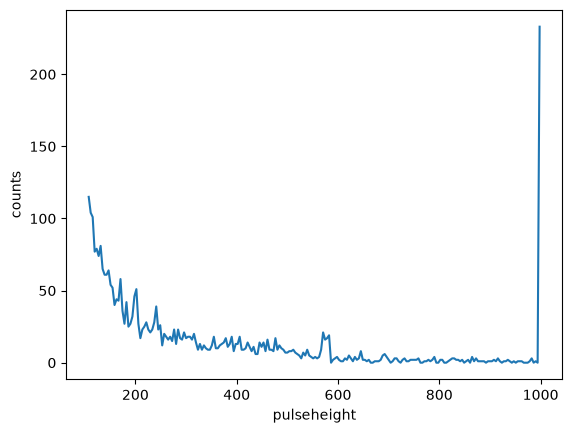

In [40]:
plt.plot(pulseheight, counts)
plt.xlabel("pulseheight")
plt.ylabel("counts")
plt.show()

In [41]:
def lorentzian(x, x0, a, gam ):
  return a * gam**2 / ( gam**2 + ( x - x0 )**2)

def multiple_lorentzian(x, x01, a1, gam1, x02, a2, gam2, x03, a3, gam3):#, x04, a4, gam4):
    return lorentzian(x, x01, a1, gam1) + lorentzian(x, x02, a2, gam2) + lorentzian(x, x03, a3, gam3) #+ lorentzian(x, x04, a4, gam4)

In [42]:
spectrum = models.Model(multiple_lorentzian)
fit_result = spectrum.fit(counts, x=pulseheight, x01=220, a1=200, gam1=10, x02=600, a2=200, gam2=10, x03=260, a3=200, gam3=10)

print(fit_result.fit_report())

[[Model]]
    Model(multiple_lorentzian)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 20000
    # data points      = 228
    # variables        = 9
    chi-square         = 67532.1363
    reduced chi-square = 308.365919
    Akaike info crit   = 1315.55102
    Bayesian info crit = 1346.41513
    R-squared          = 0.48896215
##  Warning: uncertainties could not be estimated:
[[Variables]]
    x01:  -12004.7882 (init = 220)
    a1:    822056.389 (init = 200)
    gam1: -73550.6180 (init = 10)
    x02:   1952.67704 (init = 600)
    a2:   -763896.515 (init = 200)
    gam2: -7973.47445 (init = 10)
    x03:  -985.049486 (init = 260)
    a3:   -108765.870 (init = 200)
    gam3: -1634.69470 (init = 10)


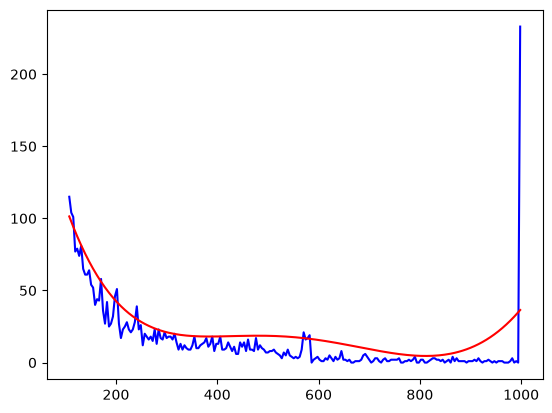

In [43]:
plt.plot(pulseheight, counts, 'b-')
plt.plot(pulseheight, fit_result.best_fit, 'r-')

plt.show()

In [44]:
pulseheight1 = fit_result.params['x01'].value
pulseheight2 = fit_result.params['x02'].value
pulseheight3 = fit_result.params['x03'].value
# pulseheight4 = fit_result.params['x04'].value

err_1 = fit_result.params['x01'].stderr
err_2 = fit_result.params['x02'].stderr
err_3 = fit_result.params['x03'].stderr
# err_4 = fit_result.params['x04'].stderr

print(pulseheight1, err_1)
print(pulseheight2, err_2)
print(pulseheight3, err_3)
# print(pulseheight4, err_4)

-12004.788166130129 None
1952.6770407961767 None
-985.0494857105577 None


In [45]:
# h to E 
a = 0.3289253213202916
a_err = 0.04530554546847939
b = 26.031476080458457

def function(x, x_err):
    y = 1/a * x - b/a 

    y_err = np.sqrt((a_err/a)**2 + (x_err/x)) * y
    y_err = float(y_err)
    return y, y_err

print(function(pulseheight2, err_2))
Energy, E_err = function(pulseheight2, err_2)

TypeError: unsupported operand type(s) for /: 'NoneType' and 'float'